# 06 · Statistical learning theory

**CSE273 Unit VI.** Well-posed learning problems and the parts of a learning system; the statistical learning framework and empirical risk minimisation; overfitting and generalisation; inductive bias and prior knowledge; PAC learning, sample complexity and the VC dimension; the No Free Lunch theorem; and how all of it guides the choice of algorithm.

Theory is usually the most abstract unit. Here every statement gets an experiment: with 630,000 labelled fields, the "true" distribution can be simulated, so the true risk of a hypothesis can actually be measured and compared with what the theory promises.

In [1]:
try:
    import groundwork
except ImportError:  # running on Kaggle
    %pip install -q git+https://github.com/LuShadowX/Groundwork
    import groundwork

import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import conviction as cn
from groundwork import data, plotting, theory
plotting.setup()

df = data.load()
rng = np.random.default_rng(6)
moist = df["Soil_Moisture"].to_numpy()
needs_water = (df[data.TARGET] != "Low").to_numpy().astype(int)   # Medium or High
print(f"share of fields that need water: {needs_water.mean():.3f}")

share of fields that need water: 0.413


## 1. Well-posed learning problems (the T-P-E framework)

A learning problem is **well-posed** when the task *T*, the performance measure *P* and the experience *E* are all pinned down.

| | Well-posed | Ill-posed version |
|---|---|---|
| T | classify a field as Low / Medium / High irrigation need | "tell us about irrigation" |
| P | balanced accuracy on unseen fields | "be good" |
| E | 630,000 labelled fields drawn from the same process as the test fields | a handful of fields from one region |

The ill-posed column can't be learned or evaluated: there is no target to fit and no way to know if it worked.

## 2. Components of a learning system

| Component | Its job | In this project |
|---|---|---|
| Data | experience to learn from | `data.load()`, stratified splits |
| Representation | how an example is described | 11 numeric + 8 one-hot categorical features |
| Hypothesis class *H* | the set of functions the learner may pick | stumps, linear models, trees, k-NN |
| Loss | what a mistake costs | 0–1 loss, cross-entropy |
| Optimiser / search | how *H* is searched | exhaustive (stumps), gradient descent (notebook 05), greedy splits (trees) |
| Evaluation | estimate of performance on new data | held-out test set, cross-validation |

## 3. The statistical learning framework

- Examples (x, y) come i.i.d. from an **unknown** distribution 𝒟.
- A hypothesis h: 𝒳 → 𝒴 has **true risk** R(h) = P₍ₓ,ᵧ₎∼𝒟[h(x) ≠ y].
- We only see a sample S of size n, so we can only compute the **empirical risk** R̂ₛ(h) = (1/n) Σ 1[h(xᵢ) ≠ yᵢ].
- **Goal:** find h with small *true* risk, using only S.

To make 𝒟 concrete, the full 630,000 fields stand in for it. Theory is simplest for binary problems, so the task for sections 3–4 and 7–8 is *does this field need water at all (Medium or High) or not (Low)?*, which is 41% positive. The first hypothesis class is **decision stumps on soil moisture**: h(x) = 1 if moisture < t (or > t), for 200 thresholds t, so |H| = 400.

In [2]:
thresholds = np.linspace(moist.min(), moist.max(), 200)

def true_risk(t, sign):
    return np.mean(theory.stump_predict(moist, t, sign) != needs_water)

risk_by_t = [true_risk(t, -1) for t in thresholds]
best_t = thresholds[int(np.argmin(risk_by_t))]
print(f"best stump in H: 'needs water' when moisture < {best_t:.1f}% · true risk {min(risk_by_t):.4f}")
print(f"(always predicting 'Low' has true risk {needs_water.mean():.4f})")

best stump in H: 'needs water' when moisture < 25.2% · true risk 0.2222
(always predicting 'Low' has true risk 0.4128)


## 4. Empirical risk minimisation (ERM)

ERM picks the hypothesis with the lowest empirical risk on the sample. The question theory answers is how close R̂ₛ(ĥ) is to R(ĥ). Measured directly, 300 times per sample size:

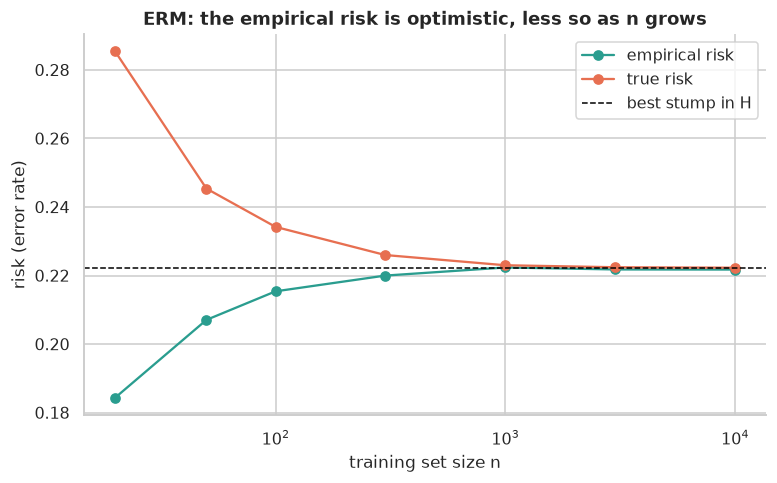

,empirical risk,true risk,gap (true − empirical)
n,,,
20,0.1843,0.2854,0.1011
50,0.2071,0.2454,0.0383
100,0.2154,0.2342,0.0188
300,0.2200,0.2260,0.0060
1000,0.2224,0.2230,0.0006
3000,0.2218,0.2224,0.0006
10000,0.2217,0.2223,0.0005


In [3]:
rows = []
for n in [20, 50, 100, 300, 1000, 3000, 10000]:
    gaps, true_r = [], []
    for _ in range(300):
        idx = rng.integers(0, len(moist), n)
        emp, t, sign = theory.erm_stump(moist[idx], needs_water[idx], thresholds)
        tr = true_risk(t, sign)
        gaps.append(tr - emp)
        true_r.append(tr)
    rows.append({"n": n, "empirical risk": np.mean(true_r) - np.mean(gaps), "true risk": np.mean(true_r), "gap (true − empirical)": np.mean(gaps)})
erm = pd.DataFrame(rows).set_index("n")

ax = erm[["empirical risk", "true risk"]].plot(marker="o", logx=True, color=["#2a9d8f", "#e76f51"])
ax.axhline(min(risk_by_t), ls="--", color="black", lw=1, label="best stump in H")
ax.set(xlabel="training set size n", ylabel="risk (error rate)", title="ERM: the empirical risk is optimistic, less so as n grows")
ax.legend()
plotting.save("g06-erm")
plt.show()
erm.round(4)

With 20 examples, the risk ERM sees on its own sample (about 0.18) is far more optimistic than its true risk (about 0.29). As n grows, the two meet at the best hypothesis in *H*, and by 10,000 examples the gap is 0.0005. This is **generalisation**: more data pins the empirical risk to the true risk.

### Overfitting and generalisation
A much richer class (decision trees of unlimited depth on all features) can drive the empirical risk to zero for any sample: it can memorise. Whether that hurts depends on the noise. Below, the same experiment runs twice: once with the real labels, which are almost a deterministic function of the features in this synthetic dataset, and once with 20% of the *training* labels flipped at random, like recording errors. The test labels are always clean.

In [4]:
from sklearn.tree import DecisionTreeClassifier

Xall, yall = data.xy(data.sample(60_000, seed=7))
yall = (yall != 0).astype(int)
X_test, y_test = Xall.iloc[:20000], yall[:20000]
flip_rng = np.random.default_rng(0)
rows = []
for noise in [0.0, 0.2]:
    for n in [1000, 5000, 20000, 40000]:
        Xn, yn = Xall.iloc[20000:20000 + n], yall[20000:20000 + n].copy()
        flip = flip_rng.random(n) < noise
        yn[flip] = 1 - yn[flip]
        for depth, label in [(6, "depth 6"), (None, "unlimited depth")]:
            m = DecisionTreeClassifier(max_depth=depth, random_state=0).fit(Xn, yn)
            rows.append({"training label noise": f"{noise:.0%}", "n": n, "tree": label,
                         "empirical risk": 1 - m.score(Xn, yn), "test risk": 1 - m.score(X_test, y_test)})
over = pd.DataFrame(rows)
over.pivot_table(index=["training label noise", "n"], columns="tree", values=["empirical risk", "test risk"]).round(4)

empirical risk                 test risk  \
tree                              depth 6 unlimited depth   depth 6   
training label noise n                                                
0%                   1000          0.0060             0.0    0.0551   
                     5000          0.0074             0.0    0.0191   
                     20000         0.0113             0.0    0.0143   
                     40000         0.0119             0.0    0.0132   
20%                  1000          0.1500             0.0    0.1678   
                     5000          0.1930             0.0    0.0542   
                     20000         0.2066             0.0    0.0192   
                     40000         0.2081             0.0    0.0146   

                                            
tree                       unlimited depth  
training label noise n                      
0%                   1000           0.0602  
                     5000           0.0251  
                     20000          0.0247  
                     40000          0.0246  
20%                  1000           0.2424  
                     5000           0.2386  
                     20000          0.2342  
                     40000          0.2354

With clean labels the unlimited tree generalises well: memorising correct answers does no harm when there is no noise to memorise. With 20% noise it still has zero empirical risk, but it has memorised the noise: its test risk is about 0.24 at every sample size and more data doesn't help. The depth-6 tree can't memorise; its empirical risk (about 0.2, mostly the flipped labels) stays honest, and its test risk falls from 0.17 to 0.015 as n grows. **Overfitting = a rich hypothesis class + noise + not enough data.**

## 5. Inductive bias

A learner can only generalise if it *prefers* some hypotheses over others: that preference is its **inductive bias**. Without it, the training data says nothing about unseen points (section 9 proves this). The same 2,000 fields given to four learners produce four different answers on every point they haven't seen:

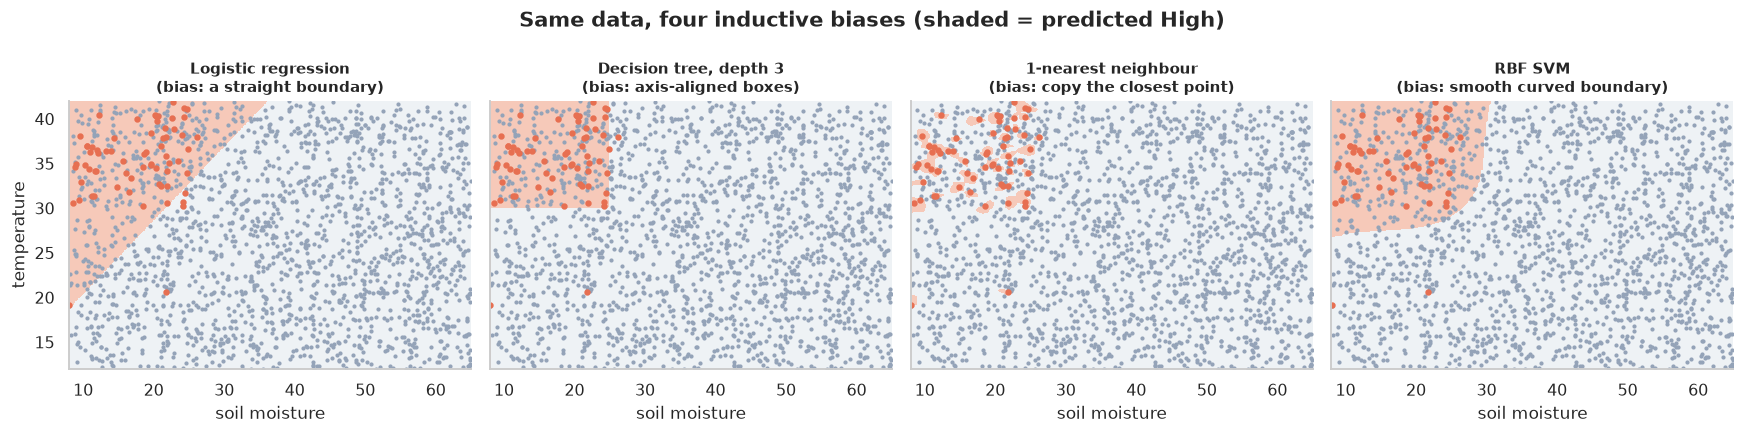

In [5]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

small = data.sample(2000, seed=8)
X2 = small[["Soil_Moisture", "Temperature_C"]].to_numpy()
y2 = (small[data.TARGET] == "High").to_numpy().astype(int)
gx, gy = np.meshgrid(np.linspace(8, 65, 250), np.linspace(12, 42, 250))
grid = np.c_[gx.ravel(), gy.ravel()]

learners = {
    "Logistic regression\n(bias: a straight boundary)": make_pipeline(StandardScaler(), LogisticRegression(class_weight="balanced")),
    "Decision tree, depth 3\n(bias: axis-aligned boxes)": DecisionTreeClassifier(max_depth=3, class_weight="balanced", random_state=0),
    "1-nearest neighbour\n(bias: copy the closest point)": make_pipeline(StandardScaler(), KNeighborsClassifier(1)),
    "RBF SVM\n(bias: smooth curved boundary)": make_pipeline(StandardScaler(), SVC(class_weight="balanced")),
}
fig, axes = plt.subplots(1, 4, figsize=(16, 4), sharey=True)
for ax, (name, model) in zip(axes, learners.items()):
    model.fit(X2, y2)
    ax.contourf(gx, gy, model.predict(grid).reshape(gx.shape), levels=[-0.5, 0.5, 1.5], colors=["#eef2f5", "#f6c9b9"])
    ax.scatter(X2[y2 == 0, 0], X2[y2 == 0, 1], s=3, color="#94a3b8")
    ax.scatter(X2[y2 == 1, 0], X2[y2 == 1, 1], s=10, color=plotting.CLASS_COLORS["High"])
    ax.set_title(name, fontsize=10)
    ax.set_xlabel("soil moisture")
axes[0].set_ylabel("temperature")
fig.suptitle("Same data, four inductive biases (shaded = predicted High)", fontweight="bold")
fig.tight_layout()
plotting.save("g06-inductive-bias")
plt.show()

Two types of bias: a **restriction bias** limits *H* itself (a linear model can't draw a box), and a **preference bias** ranks hypotheses inside *H* (a tree learner prefers shorter trees, ridge prefers small weights).

## 6. The role of prior knowledge

Inductive bias is where prior knowledge enters. Agronomy says that, all else equal, **wetter soil never needs more water**, and **hotter or windier weather never needs less**. Gradient boosting can be told exactly that through monotonic constraints. scikit-learn supports them for binary targets, so this uses the harder *High vs everything else* task, with balanced class weights. Five repeats per size; the score is balanced accuracy on 30,000 held-out fields.

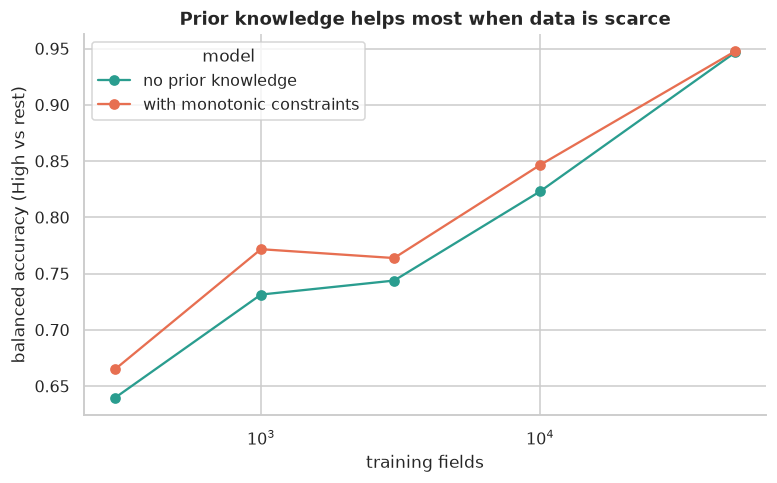

model,no prior knowledge,with monotonic constraints,gain
n,,,
300,0.6397,0.6650,0.0253
1000,0.7314,0.7718,0.0403
3000,0.7439,0.7639,0.0200
10000,0.8231,0.8466,0.0235
50000,0.9466,0.9477,0.0011


In [6]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import balanced_accuracy_score

big = data.sample(80_000, seed=9)
Xb = big[data.NUMERIC].to_numpy()
yb = (big[data.TARGET] == "High").to_numpy().astype(int)
X_eval, y_eval = Xb[:30000], yb[:30000]
mono = [0] * len(data.NUMERIC)
for col, direction in [("Soil_Moisture", -1), ("Temperature_C", 1), ("Wind_Speed_kmh", 1)]:
    mono[data.NUMERIC.index(col)] = direction

rows = []
for n in [300, 1000, 3000, 10000, 50000]:
    for name, cst in [("no prior knowledge", None), ("with monotonic constraints", mono)]:
        scores = []
        for seed in range(5):
            idx = np.random.default_rng(seed).choice(np.arange(30000, len(Xb)), n, replace=False)
            model = HistGradientBoostingClassifier(max_iter=150, monotonic_cst=cst, class_weight="balanced", random_state=seed)
            scores.append(balanced_accuracy_score(y_eval, model.fit(Xb[idx], yb[idx]).predict(X_eval)))
        rows.append({"n": n, "model": name, "mean": np.mean(scores), "sd": np.std(scores)})
prior = pd.DataFrame(rows)
piv = prior.pivot(index="n", columns="model", values="mean")
ax = piv.plot(marker="o", logx=True, color=["#2a9d8f", "#e76f51"])
ax.set(xlabel="training fields", ylabel="balanced accuracy (High vs rest)", title="Prior knowledge helps most when data is scarce")
plotting.save("g06-prior")
plt.show()
piv.assign(gain=piv["with monotonic constraints"] - piv["no prior knowledge"]).round(4)

With a few hundred to ten thousand fields, the constraints add 2–4 points: the model doesn't have to discover from scarce data what an agronomist already knows. With 50,000 fields the data teaches the rule anyway and the gain all but vanishes. (Regularisation is the same idea in statistical form: ridge regression is maximum-a-posteriori estimation under a prior that the weights are small.)

## 7. Probably Approximately Correct (PAC) learning

### The definition
A class *H* is **PAC-learnable** if, for any accuracy ε and confidence δ, there is a sample size m(ε, δ) such that with probability at least 1 − δ over the sample, the learned hypothesis has true risk within ε of the best in *H*. "Probably" is the δ, "approximately correct" is the ε.

For a finite class in the agnostic case (no perfect hypothesis, which is the realistic one), Hoeffding's inequality plus a union bound give

m ≥ (ln|H| + ln(2/δ)) / (2ε²)

and that size makes *every* hypothesis's empirical risk land within ε of its true risk at the same time. That is directly testable with the 400 moisture stumps:

In [7]:
H = 2 * len(thresholds)
eps, delta = 0.02, 0.05
m = theory.pac_sample_size(H, eps, delta, realizable=False)
print(f"|H| = {H}, ε = {eps}, δ = {delta} -> the bound asks for m = {m:,} examples")

risks_true = np.array([[true_risk(t, sgn) for t in thresholds] for sgn in (1, -1)])
trials, fails, worst = 300, 0, []
for _ in range(trials):
    idx = rng.integers(0, len(moist), m)
    xs, ys = moist[idx], needs_water[idx]
    emp = np.array([[np.mean(theory.stump_predict(xs, t, sgn) != ys) for t in thresholds] for sgn in (1, -1)])
    dev = np.abs(emp - risks_true).max()
    worst.append(dev)
    fails += dev > eps
print(f"in {trials} samples of {m:,}, the worst |empirical − true| over all {H} stumps exceeded ε in {fails} ({fails / trials:.1%}); allowed: {delta:.0%}")
print(f"largest deviation seen: {max(worst):.4f} (ε = {eps})")

|H| = 400, ε = 0.02, δ = 0.05 -> the bound asks for m = 12,101 examples


in 300 samples of 12,101, the worst |empirical − true| over all 400 stumps exceeded ε in 0 (0.0%); allowed: 5%
largest deviation seen: 0.0165 (ε = 0.02)


The guarantee holds with room to spare. The bound is a worst case over *every* possible distribution, so on one particular distribution it is conservative.

### A PAC-style guarantee in practice: `conviction.RiskGuard`
My library `conviction` turns the same idea into a tool. A model's confidence scores are calibrated on held-out data, and `RiskGuard` finds a threshold with a **certified** statement: "of the fields auto-labelled, at most α are wrong, with confidence 1 − δ". Here a logistic model auto-labels fields as *not High* when it is confident; everything else goes to an agronomist:

In [8]:
from sklearn.model_selection import train_test_split

cal = data.sample(60_000, seed=10)
Xc, yc = data.xy(cal)
yc = (yc == 2).astype(int)
X_fit, X_rest, y_fit, y_rest = train_test_split(Xc, yc, test_size=0.6, stratify=yc, random_state=0)
X_cal, X_new, y_cal, y_new = train_test_split(X_rest, y_rest, test_size=0.5, stratify=y_rest, random_state=0)
clf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)).fit(X_fit, y_fit)

conf_cal = clf.predict_proba(X_cal)[:, 0]          # confidence that the field is NOT High
guard = cn.RiskGuard(alpha=0.005, delta=0.05).calibrate(conf_cal, y_cal == 1)
print(guard.certificate)

conf_new = clf.predict_proba(X_new)[:, 0]
threshold = float(str(guard.certificate).split("score >= ")[1].split()[0])
accepted = conf_new >= threshold
print(f"on {len(X_new):,} fresh fields: auto-labelled {accepted.mean():.1%}, error among them {y_new[accepted].mean():.3%} (promised ≤ 0.5%)")

CERTIFIED
  Of the cases this guard auto-approves, at most 0.5% are wrong, with 95% confidence.
  method            selective
  threshold         accept when score >= 0.9601
  proven bound      0.44%
  automation rate   89.8% (16156/18000 calibration points)
  observed error    0.28% among those accepted
on 18,000 fresh fields: auto-labelled 89.9%, error among them 0.365% (promised ≤ 0.5%)


The promise is checked on fields the guard never saw, and it holds. That is what learning theory is for: a statement about *future* data with a stated confidence, not just a score on the data at hand.

## 8. Sample complexity

### Finite hypothesis space
The bound grows only with ln|H|, which is why even large finite classes are learnable, but with 1/ε² in the agnostic case and 1/ε in the realizable one.

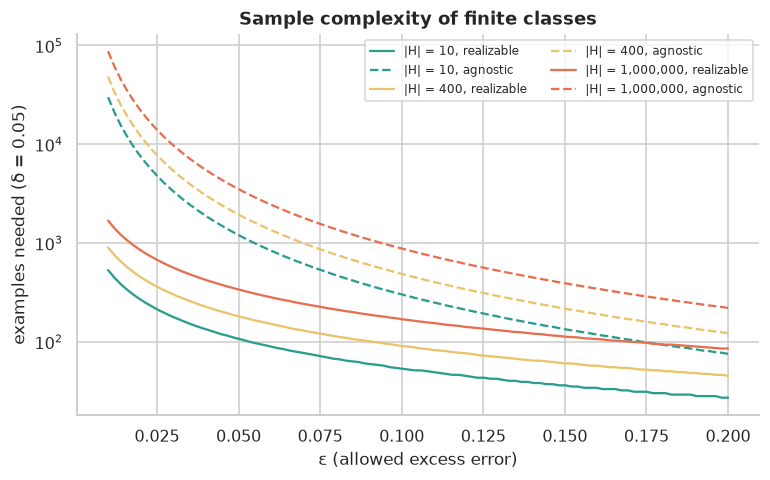

In [9]:
eps_grid = np.linspace(0.01, 0.2, 100)
fig, ax = plt.subplots()
for h_size, color in [(10, "#2a9d8f"), (400, "#e9c46a"), (10**6, "#e76f51")]:
    ax.plot(eps_grid, [theory.pac_sample_size(h_size, e, 0.05) for e in eps_grid], color=color, label=f"|H| = {h_size:,}, realizable")
    ax.plot(eps_grid, [theory.pac_sample_size(h_size, e, 0.05, realizable=False) for e in eps_grid], color=color, ls="--", label=f"|H| = {h_size:,}, agnostic")
ax.set(yscale="log", xlabel="ε (allowed excess error)", ylabel="examples needed (δ = 0.05)", title="Sample complexity of finite classes")
ax.legend(fontsize=8, ncol=2)
plotting.save("g06-sample-complexity")
plt.show()

### Infinite hypothesis space: the VC dimension
Lines in the plane form an infinite class, so ln|H| is useless. The **VC dimension** measures capacity instead: the size of the largest set of points the class can **shatter** (label in every possible way). Lines in 2-D shatter 3 points in general position but no set of 4. `theory.shattered` checks every labelling with a linear program:

3 points: shattered = True (all 8 labellings separable)
4 points: shattered = False; impossible labellings: [(0, 1, 1, 0), (1, 0, 0, 1)]


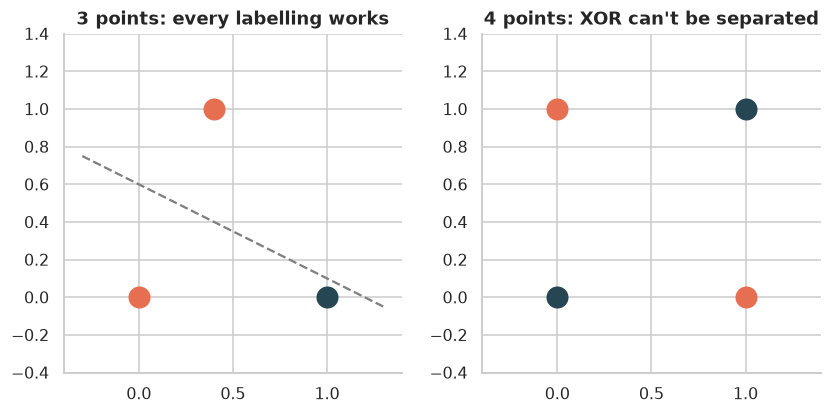

examples needed for lines in 2-D (d = 3, ε = δ = 0.05): 3,851
for a linear model on all 43 encoded features (d = 44): 56,478


In [10]:
three = np.array([[0, 0], [1, 0], [0.4, 1]])
four = np.array([[0, 0], [1, 0], [0, 1], [1, 1]])
ok3, _ = theory.shattered(three)
ok4, failed = theory.shattered(four)
print(f"3 points: shattered = {ok3} (all {2**3} labellings separable)")
print(f"4 points: shattered = {ok4}; impossible labellings: {failed}")

fig, axes = plt.subplots(1, 2, figsize=(9, 4))
for ax, pts, labels, title in [(axes[0], three, (1, 0, 1), "3 points: every labelling works"), (axes[1], four, failed[0], "4 points: XOR can't be separated")]:
    for (x0, y0), lab in zip(pts, labels):
        ax.scatter(x0, y0, s=180, color=plotting.CLASS_COLORS["High"] if lab else plotting.ACCENT, zorder=3)
    ax.set(xlim=(-0.4, 1.4), ylim=(-0.4, 1.4), title=title)
    ax.set_aspect("equal")
axes[0].plot([-0.3, 1.3], [0.75, -0.05], ls="--", color="grey")
plotting.save("g06-vc")
plt.show()

print("examples needed for lines in 2-D (d = 3, ε = δ = 0.05):", f"{theory.vc_sample_size(3, 0.05, 0.05):,}")
print("for a linear model on all 43 encoded features (d = 44):", f"{theory.vc_sample_size(44, 0.05, 0.05):,}")

Linear classifiers in *d* dimensions have VC dimension d + 1, so the 43 encoded features give 44. The (very loose) bound asks for tens of thousands of examples, and the competition has 630,000. That is consistent with notebook 05, where the linear model's training and test scores were almost the same.

## 9. The No Free Lunch theorem

Averaged over **all** possible target functions, every learning algorithm has the same accuracy on points it hasn't seen. A tiny world makes this checkable exactly: 3 binary features give 8 possible inputs; train on 4, test on the other 4, and enumerate all 2⁸ = 256 ways the labels could be.

In [11]:
inputs = np.array(list(itertools.product([0, 1], repeat=3)))
train_idx, test_idx = [0, 3, 5, 6], [1, 2, 4, 7]
nearest = lambda Xtr, ytr, Xte: ytr[np.abs(Xte[:, None, :] - Xtr[None, :, :]).sum(-1).argmin(1)]
nfl_learners = {
    "always predict 0": lambda Xtr, ytr, Xte: np.zeros(len(Xte), int),
    "majority class": lambda Xtr, ytr, Xte: np.full(len(Xte), int(ytr.mean() >= 0.5)),
    "1-nearest neighbour": nearest,
    "decision tree": lambda Xtr, ytr, Xte: DecisionTreeClassifier(random_state=0).fit(Xtr, ytr).predict(Xte) if len(set(ytr)) > 1 else np.full(len(Xte), ytr[0]),
    "anti-learner (opposite of 1-NN)": lambda Xtr, ytr, Xte: 1 - nearest(Xtr, ytr, Xte),
}
results = {name: [] for name in nfl_learners}
for labels in itertools.product([0, 1], repeat=8):
    y_all = np.array(labels)
    for name, learn in nfl_learners.items():
        pred = learn(inputs[train_idx], y_all[train_idx], inputs[test_idx])
        results[name].append(np.mean(pred == y_all[test_idx]))
pd.DataFrame({"mean off-training-set accuracy over all 256 targets": {k: np.mean(v) for k, v in results.items()}})

,mean off-training-set accuracy over all 256 targets
always predict 0,0.5
majority class,0.5
1-nearest neighbour,0.5
decision tree,0.5
anti-learner (opposite of 1-NN),0.5


Exactly 0.5 for every learner, including one built to be wrong. No algorithm is better in general; one is better only on problems whose structure matches its inductive bias.

In practice, rankings flip between datasets. Three models on four datasets (scikit-learn's two curved toy shapes, a problem whose true boundary is a straight line with noise, and the irrigation data), 5-fold cross-validated balanced accuracy:

In [12]:
from sklearn.datasets import make_moons, make_circles
from sklearn.model_selection import cross_val_score

Xi, yi = data.xy(data.sample(6000, seed=11))
datasets = {
    "moons": make_moons(1500, noise=0.25, random_state=0),
    "circles": make_circles(1500, noise=0.1, factor=0.5, random_state=0),
    "linear": (lambda X_: (X_, (X_ @ np.linspace(-1, 1, 10) + np.random.default_rng(1).normal(0, 0.5, 1500) > 0).astype(int)))(np.random.default_rng(0).normal(size=(1500, 10))),
    "irrigation": (Xi.to_numpy(), yi),
}
models = {
    "logistic regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)),
    "k-NN (k = 15)": make_pipeline(StandardScaler(), KNeighborsClassifier(15)),
    "decision tree (depth 8)": DecisionTreeClassifier(max_depth=8, random_state=0),
}
nfl_table = pd.DataFrame({dname: {mname: cross_val_score(mdl, X_, y_, cv=5, scoring="balanced_accuracy").mean() for mname, mdl in models.items()}
                          for dname, (X_, y_) in datasets.items()})
print("winner per dataset:", nfl_table.idxmax().to_dict())
nfl_table.round(3)

winner per dataset: {'moons': 'k-NN (k = 15)', 'circles': 'k-NN (k = 15)', 'linear': 'logistic regression', 'irrigation': 'decision tree (depth 8)'}


,moons,circles,linear,irrigation
logistic regression,0.865,0.487,0.919,0.779
k-NN (k = 15),0.941,0.991,0.863,0.527
decision tree (depth 8),0.917,0.981,0.759,0.937


Different datasets, different winners: the bias that suits curved toy shapes is wrong for a linear problem, and the irrigation data, with its thresholds and interactions, favours the tree.

## 10. Choosing algorithms based on data and assumptions

| If the data… | Prefer | Because |
|---|---|---|
| is small | simple models, strong priors (constraints, regularisation) | low variance, small sample complexity |
| has a roughly linear relation | linear / logistic regression | right bias, interpretable coefficients |
| has thresholds and interactions (this dataset) | trees and tree ensembles | axis-aligned splits match the structure |
| has a meaningful distance | k-NN, kernel methods | similar inputs → similar outputs |
| must come with guarantees | calibrated models + conformal methods (`conviction`) | distribution-free error bounds |

### Occam's razor
Among models that explain the data equally well, prefer the simplest. In practice: the **one-standard-error rule**, picking the simplest model whose cross-validated score is within one standard error of the best.

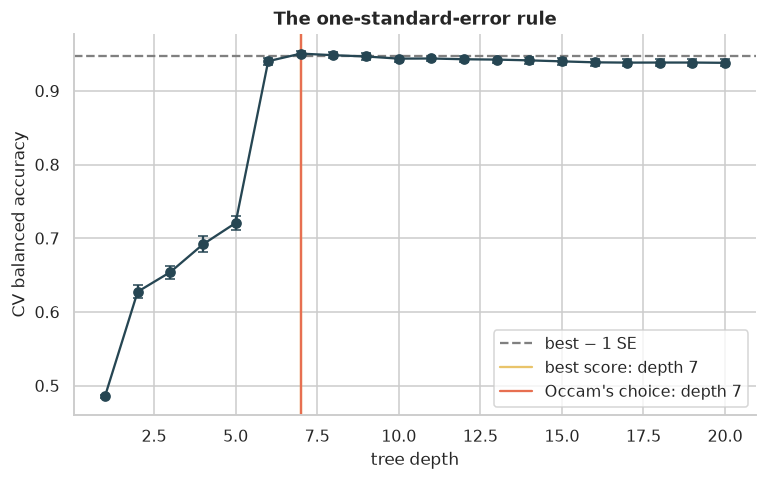

best depth 7 (0.9507) vs Occam's choice 7 (0.9507)
depths within one SE of the best: [7, 8]


In [13]:
Xo, yo = data.xy(data.sample(20_000, seed=12))
depth_rows = []
for depth in range(1, 21):
    sc = cross_val_score(DecisionTreeClassifier(max_depth=depth, random_state=0), Xo, yo, cv=5, scoring="balanced_accuracy")
    depth_rows.append({"depth": depth, "mean": sc.mean(), "se": sc.std(ddof=1) / np.sqrt(len(sc))})
occ = pd.DataFrame(depth_rows).set_index("depth")
best_depth = occ["mean"].idxmax()
cutoff = occ.loc[best_depth, "mean"] - occ.loc[best_depth, "se"]
simplest = occ.index[occ["mean"] >= cutoff].min()

fig, ax = plt.subplots()
ax.errorbar(occ.index, occ["mean"], yerr=occ["se"], fmt="o-", color=plotting.ACCENT, capsize=3)
ax.axhline(cutoff, ls="--", color="grey", label="best − 1 SE")
ax.axvline(best_depth, color="#e9c46a", label=f"best score: depth {best_depth}")
ax.axvline(simplest, color="#e76f51", label=f"Occam's choice: depth {simplest}")
ax.set(xlabel="tree depth", ylabel="CV balanced accuracy", title="The one-standard-error rule")
ax.legend()
plotting.save("g06-occam")
plt.show()
print(f"best depth {best_depth} ({occ.loc[best_depth, 'mean']:.4f}) vs Occam's choice {simplest} ({occ.loc[simplest, 'mean']:.4f})")
print("depths within one SE of the best:", occ.index[occ["mean"] >= cutoff].tolist())

On this data the score climbs steeply up to depth 7 and then drifts down, so the best depth is also the simplest one within one standard error and the two choices agree. The rule only changes the answer when several sizes tie, which is common on smaller or noisier datasets. Either way the principle holds: nothing deeper than depth 7 earns its extra complexity.

| Syllabus topic | Where |
|---|---|
| Well-posed learning problems (T-P-E) | 1 |
| Components of a learning system | 2 |
| Statistical learning framework | 3 |
| Empirical risk minimisation, overfitting and generalisation | 4 |
| Inductive bias | 5 |
| Role of prior knowledge | 6 |
| PAC learning | 7 (bound checked empirically; `conviction.RiskGuard`) |
| Sample complexity: finite H, VC dimension | 8 |
| No Free Lunch theorem | 9 (exhaustive check on a small world) |
| Choosing algorithms, Occam's razor | 10 |